# Практическая работа № 6. Классификация текстов

**Уровень:** B (данные заданы)
**Цель:** собрать пайплайн обработки текста (очистка → токенизация → нормализация → векторизация TF-IDF) и обучить на нём классификатор тональности отзывов.

**Данные:** `data/reviews.csv` — 600 коротких русскоязычных отзывов с меткой тональности (1 — положительный, 0 — отрицательный). Корпус **синтетический** (собран скриптом `src/make_reviews.py` из готовых фраз): в нём есть смешанные отзывы, фразы с отрицанием («не плохо», «не рекомендую»), рейтинги-цифры и около 4% намеренных ошибок разметки.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("../data/reviews.csv")
print("Размер корпуса:", df.shape)
print("Доля классов:\n", df["label"].value_counts(normalize=True).round(3))
df.head(3)

Размер корпуса: (600, 2)
Доля классов:
 label
1    0.565
0    0.435
Name: proportion, dtype: float64


                                                text  label
0  Купили всей семьёй. Не рекомендую, деньги на в...      1
1  Пользуюсь уже 2 месяца. Купил маме, она в полн...      1
2  Остались только положительные впечатления. Дос...      1

## 1. Разбиение train / test — до векторизации
Словарь и IDF-веса считаются **только по train** (векторизатор будет внутри `Pipeline`). Очистка текста — это правила без статистики по корпусу, поэтому её можно применять к любому тексту независимо.

In [2]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
print("train:", len(train_df), "| test:", len(test_df))

train: 480 | test: 120


## 2. Очистка текста
Шаги: приведение к нижнему регистру → удаление пунктуации, цифр и латиницы → токенизация по пробелам → удаление стоп-слов.

**Важно про стоп-слова:** в списке намеренно **нет** «не», «ни», «нет» — для тональности отрицание меняет смысл («не рекомендую» — это отрицательный отзыв). Ниже есть эксперимент, который показывает, что будет, если их всё же удалить.

In [3]:
STOP_WORDS = {
    "и", "в", "во", "на", "с", "со", "к", "ко", "по", "за", "из", "у", "о", "об", "от", "до", "для", "при", "про",
    "а", "но", "да", "или", "то", "что", "это", "как", "так", "же", "бы", "ли", "вот", "все", "всё", "он", "она",
    "оно", "они", "я", "мы", "вы", "ты", "мой", "наш", "этот", "тот", "был", "была", "было", "были", "есть",
    "его", "её", "их", "мне", "нам", "там", "тут", "уже", "ещё", "только", "чем", "если",
}

def tokenize(text, stop_words=STOP_WORDS):
    text = text.lower()                          # нижний регистр
    text = re.sub(r"[^а-яё\s]", " ", text)       # убираем пунктуацию, цифры, латиницу
    return [w for w in text.split() if w not in stop_words]

example = df["text"].iloc[1]
print("Исходный текст :", example)
print("После очистки  :", tokenize(example))

Исходный текст : Пользуюсь уже 2 месяца. Купил маме, она в полном восторге. Качество на высоте, рекомендую всем... Оценка: 4 из 5.
После очистки  : ['пользуюсь', 'месяца', 'купил', 'маме', 'полном', 'восторге', 'качество', 'высоте', 'рекомендую', 'всем', 'оценка']


## 3. Нормализация (упрощённый стемминг)
Готового русского стеммера в стандартном scikit-learn нет, поэтому реализован **простейший стеммер**: отбрасывает типичные окончания, если остаётся основа не короче 3 букв. Он грубый (не заменяет полноценную лемматизацию, например `pymorphy3`), но приводит «рекомендую / рекомендуют» к одной основе.

In [4]:
SUFFIXES = sorted(["ами", "ями", "ого", "его", "ому", "ему", "ыми", "ими", "ать", "ять", "ить", "еть", "ует", "ают", "яют",
                   "ает", "ала", "ало", "али", "ила", "или", "ило", "ов", "ев", "ей", "ом", "ем", "ах", "ях", "ий", "ый",
                   "ой", "ая", "яя", "ое", "ее", "ые", "ие", "ую", "юю", "ам", "ям", "ою", "ею", "ую", "ют", "ут", "ет",
                   "ит", "а", "я", "о", "е", "ы", "и", "у", "ю", "ь", "й"], key=len, reverse=True)

def stem(word):
    for s in SUFFIXES:
        if word.endswith(s) and len(word) - len(s) >= 3:
            return word[:-len(s)]
    return word

def preprocess(text, use_stem=True, stop_words=STOP_WORDS):
    tokens = tokenize(text, stop_words)
    return " ".join(stem(w) for w in tokens) if use_stem else " ".join(tokens)

print("Исходный :", example)
print("Основы   :", preprocess(example))

Исходный : Пользуюсь уже 2 месяца. Купил маме, она в полном восторге. Качество на высоте, рекомендую всем... Оценка: 4 из 5.
Основы   : пользуюс месяц купил мам полн восторг качеств высот рекоменд всем оценк


## 4. Сравнение вариантов предобработки
Один и тот же классификатор (`MultinomialNB`) и один и тот же TF-IDF (`min_df=2`, `max_df=0.9` — слова, встречающиеся в менее чем 2 документах или в более чем 90%, отбрасываются). Меняется только предобработка. Так как test всего из 120 документов, сравниваем по **5-кратной кросс-валидации на train** (векторизатор внутри каждого фолда обучается заново — без утечки) и дополнительно по test.

In [5]:
STOP_BAD = STOP_WORDS | {"не", "ни", "нет"}      # «плохой» список: удаляет отрицания

variants = {
    "1. Без очистки (сырой текст)": (lambda t: t, (1, 1)),
    "2. Очистка + стоп-слова": (lambda t: preprocess(t, use_stem=False), (1, 1)),
    "3. Очистка + стоп-слова + стемминг": (lambda t: preprocess(t), (1, 1)),
    "4. Вариант 3 + биграммы (1–2 слова)": (lambda t: preprocess(t), (1, 2)),
    "5. Вариант 3, но «не/ни/нет» удалены": (lambda t: preprocess(t, stop_words=STOP_BAD), (1, 1)),
}

def make_pipe(ngram):
    return Pipeline([("tfidf", TfidfVectorizer(min_df=2, max_df=0.9, ngram_range=ngram)),
                     ("nb", MultinomialNB())])

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, (prep, ngram) in variants.items():
    Xtr = train_df["text"].map(prep); Xte = test_df["text"].map(prep)
    pipe = make_pipe(ngram)
    cv_acc = cross_val_score(pipe, Xtr, train_df["label"], cv=cv, scoring="accuracy").mean()
    pipe.fit(Xtr, train_df["label"])
    pred = pipe.predict(Xte)
    rows.append({"вариант": name, "CV accuracy (train)": cv_acc,
                 "test accuracy": accuracy_score(test_df["label"], pred),
                 "test F1": f1_score(test_df["label"], pred),
                 "размерность": len(pipe.named_steps["tfidf"].vocabulary_)})
pd.DataFrame(rows).set_index("вариант").round(3)

                                      CV accuracy (train)  test accuracy  test F1  размерность
вариант                                                                                       
1. Без очистки (сырой текст)                        0.931          0.967    0.971          137
2. Очистка + стоп-слова                             0.933          0.967    0.971          127
3. Очистка + стоп-слова + стемминг                  0.938          0.958    0.963          116
4. Вариант 3 + биграммы (1–2 слова)                 0.944          0.967    0.971          543
5. Вариант 3, но «не/ни/нет» удалены                0.935          0.958    0.963          114

**Вывод по сравнению вариантов предобработки.**

| Вариант | CV accuracy | Размерность |
|---|---|---|
| 1. Сырой текст | 0,931 | 137 |
| 2. Очистка + стоп-слова | 0,933 | 127 |
| 3. + стемминг | 0,938 | 116 |
| 4. + биграммы | **0,944** | 543 |
| 5. «не/ни/нет» удалены | 0,935 | 114 |

- Все варианты отличаются **менее чем на 1,3 процентного пункта**, а это сопоставимо с разбросом оценки на 480 документах — значит, уверенно сказать, что один вариант «лучше» другого, нельзя. Основная причина — синтетический корпус: тональность в нём задаётся яркими «маркерными» словами (отвратительно, отлично, рекомендую), которые модель находит при любой предобработке. На реальных отзывах разница обычно заметнее.
- Тем не менее тенденция логична: стемминг уменьшил словарь (127 → 116) без потери качества; биграммы дали лучший результат, потому что позволяют увидеть пары вроде «не рекоменд» (отрицание вместе со словом), но ценой роста размерности с 116 до 543.
- **Удаление отрицаний** («не», «ни», «нет») снизило CV accuracy с 0,938 до 0,935 — почти незаметно здесь, но по смыслу это опасная операция: без «не» фразы «рекомендую» и «не рекомендую» становятся неразличимыми. Поэтому в основном пайплайне отрицания сохранены.
- Вариант 1 (сырой текст) работает почти так же хорошо, потому что `TfidfVectorizer` сам приводит текст к нижнему регистру и отбрасывает пунктуацию; значимый вклад очистки — в удалении цифр («Оценка: 4 из 5») и стоп-слов.

## 5. Итоговая модель и её качество
Для финальной модели выбран **вариант 4** (очистка + стоп-слова без отрицаний + стемминг + униграммы и биграммы) — у него лучшая кросс-валидационная accuracy.

In [6]:
final = make_pipe((1, 2))
X_tr = train_df["text"].map(preprocess); X_te = test_df["text"].map(preprocess)
final.fit(X_tr, train_df["label"])
pred = final.predict(X_te)
proba_pos = final.predict_proba(X_te)[:, 1]

tfidf = final.named_steps["tfidf"]
print("Размерность признакового пространства (число слов и биграмм в словаре):", len(tfidf.vocabulary_))
print("Форма матрицы train:", tfidf.transform(X_tr).shape, "| test:", tfidf.transform(X_te).shape)
print()
print(classification_report(test_df["label"], pred, target_names=["отрицательный", "положительный"], digits=3))

Размерность признакового пространства (число слов и биграмм в словаре): 543
Форма матрицы train: (480, 543) | test: (120, 543)

               precision    recall  f1-score   support

отрицательный      0.962     0.962     0.962        52
положительный      0.971     0.971     0.971        68

     accuracy                          0.967       120
    macro avg      0.966     0.966     0.966       120
 weighted avg      0.967     0.967     0.967       120



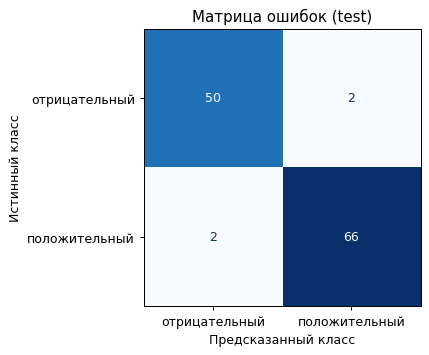

In [7]:
cm = confusion_matrix(test_df["label"], pred)
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=["отрицательный", "положительный"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Матрица ошибок (test)")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.show()

In [8]:
# Какие слова модель считает самыми «положительными» и «отрицательными»
nb = final.named_steps["nb"]
words = np.array(tfidf.get_feature_names_out())
diff = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
print("Самые «положительные» признаки:", list(words[np.argsort(diff)[-10:][::-1]]))
print("Самые «отрицательные» признаки:", list(words[np.argsort(diff)[:10]]))

Самые «положительные» признаки: ['удобн', 'удобн быстр', 'приложен удобн', 'которым', 'лучш сервис', 'которым пользовалс', 'сервис которым', 'пользовалс', 'лучш', 'отличн']
Самые «отрицательные» признаки: ['дня', 'больш не', 'прид', 'больш', 'не прид', 'обслуживан отвратительн', 'отвратительн', 'отвратительн больш', 'не соответств', 'вернул']


**Что выучила модель.** Положительный класс определяют слова и пары «удобн», «лучш сервис», «отличн»; отрицательный — «отвратительн», «больш не прид» (из «больше не приду»), «не соответств», «вернул». Это осмысленные признаки, модель опирается на содержание отзывов, а не на случайные слова. Признак «дня» в отрицательных объясняется фразой «сломалось через 3 дня» — слово случайно оказалось привязанным к одной жалобе.

**Качество:** accuracy на test ≈ 0,967, F1 по обоим классам ≈ 0,96–0,97, размерность признакового пространства — 543 признака (слова и биграммы). Классы умеренно несбалансированы (56% / 44%), поэтому одной accuracy мало — precision и recall для каждого класса показаны выше и почти одинаковы.

## 6. Анализ ошибок модели
На test модель ошиблась всего 4 раза, а нужно разобрать 5 ошибок. Поэтому к ним добавлена самая уверенная ошибка на **train** по out-of-fold предсказаниям (кросс-валидация: модель этот документ при обучении не видела, поэтому оценка честная). Первыми показаны самые уверенные ошибки.

In [9]:
from sklearn.model_selection import cross_val_predict

# ошибки на test
err_test = test_df.assign(pred=pred, p_pos=proba_pos, источник="test")
# ошибки out-of-fold на train
oof_p = cross_val_predict(make_pipe((1, 2)), X_tr, train_df["label"], cv=cv, method="predict_proba")[:, 1]
err_train = train_df.assign(pred=(oof_p >= 0.5).astype(int), p_pos=oof_p, источник="train (out-of-fold)")

err = pd.concat([err_test, err_train])
err = err[err["label"] != err["pred"]].copy()
err["conf"] = np.where(err["pred"] == 1, err["p_pos"], 1 - err["p_pos"])      # уверенность модели в своей ошибке
print("Ошибок на test:", (err["источник"] == "test").sum(), "из", len(test_df))
print("Ошибок out-of-fold на train:", (err["источник"] != "test").sum(), "из", len(train_df), "\n")

shown = pd.concat([err[err["источник"] == "test"].sort_values("conf", ascending=False),
                   err[err["источник"] != "test"].sort_values("conf", ascending=False).head(1)])
for i, (_, r) in enumerate(shown.iterrows(), 1):
    print(f"Ошибка {i} [{r['источник']}]: метка = {r['label']}, предсказано = {r['pred']}, P(положительный) = {r['p_pos']:.2f}")
    print("  ", r["text"], "\n")

Ошибок на test: 4 из 120
Ошибок out-of-fold на train: 27 из 480 

Ошибка 1 [test]: метка = 1, предсказано = 0, P(положительный) = 0.00
   Хуже сервиса я не встречал. Не работает с первого дня, вернул обратно. Доставку ждал две недели, никто не отвечал! 

Ошибка 2 [test]: метка = 0, предсказано = 1, P(положительный) = 0.98
   Курьер вежливый, заказ привезли горячим. Приложение удобное и быстрое. Спасибо за быструю и чёткую работу!! 

Ошибка 3 [test]: метка = 1, предсказано = 0, P(положительный) = 0.04
   Не рекомендую, деньги на ветер. Товар не соответствует описанию, пришлось возвращать! 

Ошибка 4 [test]: метка = 0, предсказано = 1, P(положительный) = 0.54
   Совсем не плохо, даже лучше, чем ожидал. Не рекомендую, деньги на ветер. Персонал невежливый, в зале грязно!! 

Ошибка 5 [train (out-of-fold)]: метка = 0, предсказано = 1, P(положительный) = 1.00
   Совсем не плохо, даже лучше, чем ожидал. Приложение удобное и быстрое. Не ожидал такого качества за эти деньги! 



**Разбор ошибок и гипотезы о причинах.**

| № | Что в тексте | Метка / предсказание | Гипотеза о причине |
|---|---|---|---|
| 1 | «Хуже сервиса я не встречал. Не работает с первого дня… ждал две недели» — явная жалоба | 1 / 0 | **Ошибка разметки.** Текст однозначно отрицательный, модель права. В корпусе есть намеренно неверные метки (~4%) |
| 2 | «Курьер вежливый… приложение удобное… спасибо за быструю и чёткую работу!!» — явная похвала | 0 / 1 | **Ошибка разметки**, как в №1: модель с вероятностью 0,98 уверена в положительном классе, и по тексту она права |
| 3 | «Не рекомендую, деньги на ветер. Товар не соответствует описанию» | 1 / 0 | **Ошибка разметки.** Две явные жалобы с отрицанием, метка «положительный» не соответствует тексту |
| 4 | Смешанный: «Совсем не плохо, даже лучше, чем ожидал» + «Не рекомендую» + «Персонал невежливый, в зале грязно» | 0 / 1 (P = 0,54) | **Настоящая ошибка модели** на границе классов. Положительная фраза содержит слова «лучше» и «не плохо», а отрицательных фраз две, но они «разбавлены». Модель Bag of Words считает слова, но не понимает, что «не плохо» — это положительное, а «не рекомендую» — отрицательное, и не взвешивает фразы по важности: отрицание «не» встречается в обоих классах |
| 5 (train, out-of-fold) | «Совсем не плохо, даже лучше, чем ожидал. Приложение удобное и быстрое. Не ожидал такого качества» | 0 / 1 (P = 1,00) | **Ошибка разметки.** Три положительные фразы, метка «отрицательный» |

**Общий вывод по ошибкам.** Из пяти разобранных ошибок четыре похожи на ошибки разметки, а не на промахи модели — на таком «чистом» синтетическом корпусе это ожидаемо: больше ошибиться ей почти не на чем. Единственная содержательная ошибка (№4) — смешанный отзыв с отрицанием, и это типичное слабое место Bag of Words / TF-IDF: порядок слов и область действия отрицания теряются. Улучшить это можно биграммами/триграммами, моделями на основе последовательностей или более сложными представлениями текста (эмбеддинги).

*Ограничения:* корпус синтетический и построен из ограниченного набора фраз, поэтому высокая accuracy не гарантирует такого же качества на реальных отзывах; test состоит всего из 120 документов.

## 7. Итоговый вывод

- Реализован полный пайплайн: нижний регистр → удаление пунктуации и цифр → удаление стоп-слов (с сохранением отрицаний) → упрощённый стемминг → TF-IDF с `min_df=2`, `max_df=0.9` → `MultinomialNB`.
- Векторизатор обучается только на train (внутри `Pipeline`), поэтому утечки из test нет; размерность признакового пространства — 543.
- Качество на test: accuracy ≈ 0,967, F1 ≈ 0,97; варианты предобработки различаются слабо (< 1,3 п. п.), лучший по кросс-валидации — с биграммами.
- Разобраны 5 ошибок: 4 из них — вероятные ошибки разметки, 1 — реальная слабость Bag of Words на смешанном отзыве с отрицанием.